# Музыкальные семантические признаки и рекомендательная система

**Решение:** [music_recommendation_semantics.ipynb](./music_recommendation_semantics.ipynb)

## Цель

Собрать небольшой музыкальный датасет, извлечь низкоуровневые и семантические признаки, исследовать их, построить простую content-based рекомендательную систему и честно оценить, насколько признаки отражают реальную музыкальную похожесть.

## Задачи

1. Выбрать и описать датасет из 50–100 треков.
2. Спроектировать набор признаков: жанр, настроение, контекст, атмосфера, темп, энергия, инструментальность, эпоха, аудиоэмбеддинги.
3. Реализовать воспроизводимый пайплайн извлечения признаков.
4. Провести EDA: распределения, корреляции, выбросы, ограничения.
5. Построить similarity-модель, визуализировать пространство, привести примеры рекомендаций и выводы.

## Стек

`Python`, `pandas`, `numpy`, `librosa`, `torch`, `transformers`, `scikit-learn`, `umap-learn`, `matplotlib`, `seaborn`.

## Данные

- 80 треков из **Free Music Archive (FMA)**, подмножество `fma_small`.
- 8 жанров по 10 треков: Electronic, Experimental, Folk, Hip-Hop, Instrumental, International, Pop, Rock.
- 30-секундные mp3 с открытыми лицензиями.
- Метаданные: исполнитель, альбом, жанр, дата релиза, URL, лицензия, прослушивания.


In [1]:
import subprocess
import sys

if "google.colab" in sys.modules:
    subprocess.run(["apt-get", "-qq", "-y", "install", "ffmpeg"], check=False)
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "librosa", "soundfile", "remotezip", "umap-learn", "transformers>=4.40"],
        check=True,
    )


## 1. Данные

### 1.1. Источник

Используется **Free Music Archive (FMA)** — открытый архив музыки с метаданными и прямыми ссылками на аудио. Выбрано подмножество `fma_small`: 30-секундные mp3, которых достаточно для сравнения тембра, ритма и настроения, но которые не требуют хранить полные треки.

FMA удобен для учебного прототипа: открытые лицензии, стабильные метаданные, прямой доступ к аудио и возможность честно указать происхождение каждого трека. Коммерческие API (Spotify, Deezer) в ходе работы дали ограничения: preview-ссылки истекли или возвращали `403`, часть каталога недоступна, а условия использования усложняют воспроизводимость.

### 1.2. Схема отбора

- 8 верхнеуровневых жанров FMA.
- По 10 треков на жанр.
- Не более 2 треков одного исполнителя.
- Сортировка внутри жанра по числу прослушиваний.
- Только треки, для которых есть аудио в `fma_small`.

Итог: ровно **80 треков**, сбалансированных по жанрам, но не по исполнителям и не по настроению.

### 1.3. Поля датасета

| Поле | Смысл |
|---|---|
| `track_uid`, `track_id` | идентификаторы FMA |
| `title`, `artist`, `album` | метаданные |
| `genre` | верхнеуровневый жанр FMA |
| `release_date`, `year`, `era` | дата релиза и десятилетие |
| `listens`, `favorites` | популярность в FMA |
| `duration_sec` | полная длительность трека |
| `instrumental_tag` | флаг инструментальности из метаданных |
| `license`, `track_url` | лицензия и страница трека |
| `audio_path`, `audio_member` | локальный путь и путь внутри FMA |
| `genres_all` | все жанровые теги FMA |

### 1.4. Ограничения данных

- 30-секундные фрагменты не описывают развитие композиции.
- Верхнеуровневый жанр FMA — широкий и иногда шумный.
- Жанры сбалансированы искусственно, а настроения — нет.
- У 43 из 80 треков нет даты релиза, поэтому эпоха известна не для всех.
- Нет пользовательских взаимодействий, поэтому качество рекомендаций оценивается косвенно, через совпадение метаданных.


In [2]:
from pathlib import Path
import io
import json
import time
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import torch
import librosa
from remotezip import RemoteZip
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import pairwise_distances, silhouette_score
import umap
from IPython.display import display
from transformers import (
    AutoFeatureExtractor,
    AutoModelForAudioClassification,
    ClapModel,
    ClapProcessor,
)

%matplotlib inline

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT / "music_recommendation_semantics").exists():
    ROOT = ROOT / "music_recommendation_semantics"

DATA_DIR = ROOT / "data"
FMA_DIR = DATA_DIR / "fma"
AUDIO_DIR = ROOT / "audio"
FIG_DIR = ROOT / "figures"
for path in (DATA_DIR, FMA_DIR, AUDIO_DIR, FIG_DIR):
    path.mkdir(parents=True, exist_ok=True)

TRACKS_PATH = DATA_DIR / "tracks.csv"
ENRICHED_PATH = DATA_DIR / "tracks_enriched.csv"
CLAP_PATH = DATA_DIR / "clap_embeddings.npy"
DSP_PATH = DATA_DIR / "dsp_features.npz"
SEM_PATH = DATA_DIR / "semantic_probabilities.npz"
CONFIG_PATH = DATA_DIR / "feature_config.json"

FORCE_REBUILD = False
FORCE_EXTRACTION = False


W1025 15:06:38.420000 20767 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


### 1.5. Загрузка датасета

Код ниже скачивает метаданные FMA, отбирает треки по описанным правилам и загружает только выбранные mp3 через HTTP Range. При наличии локальных файлов шаг пропускается.


In [3]:
META_URL = "https://os.unil.cloud.switch.ch/fma/fma_metadata.zip"
SMALL_URL = "https://os.unil.cloud.switch.ch/fma/fma_small.zip"
GENRES = ["Pop", "Rock", "Hip-Hop", "Electronic", "Folk", "Experimental", "Instrumental", "International"]
PER_GENRE = 10
MAX_PER_ARTIST = 2


def ensure_metadata():
    needed = [FMA_DIR / "tracks.csv", FMA_DIR / "raw_tracks.csv", FMA_DIR / "genres.csv"]
    if all(path.exists() for path in needed):
        return
    archive_path = DATA_DIR / "fma_metadata.zip"
    response = requests.get(META_URL, stream=True, timeout=180)
    response.raise_for_status()
    with open(archive_path, "wb") as target:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                target.write(chunk)
    with zipfile.ZipFile(archive_path) as archive:
        for name in ["tracks.csv", "raw_tracks.csv", "genres.csv"]:
            archive.extract(name, FMA_DIR)


def load_metadata():
    tracks = pd.read_csv(FMA_DIR / "tracks.csv", header=[0, 1], index_col=0)
    raw = pd.read_csv(
        FMA_DIR / "raw_tracks.csv",
        usecols=[
            "track_id", "track_url", "track_file", "track_duration",
            "track_instrumental", "track_date_recorded", "license_title", "track_composer",
        ],
    )
    return tracks, raw.set_index("track_id")


def pick_tracks(tracks):
    subset = tracks[tracks[("set", "subset")] == "small"].copy()
    subset = subset[subset[("track", "genre_top")].isin(GENRES)]
    chosen = []
    artist_counts = {}
    for genre in GENRES:
        pool = subset[subset[("track", "genre_top")] == genre].sort_values(("track", "listens"), ascending=False)
        count = 0
        for track_id, row in pool.iterrows():
            artist = row[("artist", "name")]
            if artist_counts.get(artist, 0) >= MAX_PER_ARTIST:
                continue
            chosen.append((genre, int(track_id), row))
            artist_counts[artist] = artist_counts.get(artist, 0) + 1
            count += 1
            if count == PER_GENRE:
                break
    return chosen


def download_selected(track_ids):
    paths = {}
    with RemoteZip(SMALL_URL) as archive:
        names = set(archive.namelist())
        for index, track_id in enumerate(track_ids, 1):
            member = f"fma_small/{track_id // 1000:03d}/{track_id:06d}.mp3"
            if member not in names:
                raise FileNotFoundError(member)
            path = AUDIO_DIR / f"{track_id:06d}.mp3"
            if not path.exists() or path.stat().st_size < 1000:
                with archive.open(member) as source, open(path, "wb") as target:
                    while True:
                        chunk = source.read(1024 * 256)
                        if not chunk:
                            break
                        target.write(chunk)
            paths[track_id] = str(path)
            if index % 10 == 0:
                print("downloaded", index, "of", len(track_ids))
    return paths


def build_dataset():
    tracks, raw = load_metadata()
    chosen = pick_tracks(tracks)
    audio_paths = download_selected([track_id for _, track_id, _ in chosen])
    rows = []
    for genre, track_id, row in chosen:
        raw_row = raw.loc[track_id] if track_id in raw.index else pd.Series(dtype=object)
        rows.append({
            "track_uid": f"F{track_id:06d}",
            "track_id": track_id,
            "title": row[("track", "title")],
            "artist": row[("artist", "name")],
            "album": row[("album", "title")],
            "genre": genre,
            "genres_all": row[("track", "genres_all")],
            "release_date": row[("album", "date_released")],
            "listens": row[("track", "listens")],
            "favorites": row[("track", "favorites")],
            "duration_sec": row[("track", "duration")],
            "composer": raw_row.get("track_composer"),
            "instrumental_tag": raw_row.get("track_instrumental"),
            "license": raw_row.get("license_title"),
            "track_url": raw_row.get("track_url"),
            "track_file": raw_row.get("track_file"),
            "audio_path": audio_paths[track_id],
            "audio_member": f"fma_small/{track_id // 1000:03d}/{track_id:06d}.mp3",
        })
    data = pd.DataFrame(rows)
    data["year"] = pd.to_datetime(data["release_date"], errors="coerce").dt.year
    data["era"] = pd.cut(
        data["year"], bins=[0, 1989, 1999, 2009, 2019, 2100],
        labels=["pre-1990", "1990s", "2000s", "2010s", "2020s"],
    ).astype(str)
    data.loc[data["era"] == "nan", "era"] = "unknown"
    data.to_csv(TRACKS_PATH, index=False)
    return data


ensure_metadata()
if FORCE_REBUILD or not TRACKS_PATH.exists():
    build_dataset()

tracks = pd.read_csv(TRACKS_PATH)
tracks["audio_path"] = [str(AUDIO_DIR / f"{int(track_id):06d}.mp3") for track_id in tracks["track_id"]]
missing_audio = tracks.loc[~tracks["audio_path"].map(lambda path: Path(path).exists()), "track_id"].astype(int).tolist()
if missing_audio:
    download_selected(missing_audio)
tracks.to_csv(TRACKS_PATH, index=False)

display(tracks[["track_uid", "title", "artist", "genre", "year", "listens", "license"]].head(8))
print("tracks:", tracks.shape)
print("genres:", tracks["genre"].value_counts().to_dict())
print("audio files:", int(tracks["audio_path"].map(lambda path: Path(path).exists()).sum()), "of", len(tracks))


,track_uid,title,artist,genre,year,listens,license
0,F054033,Snow Wave,alright lover,Pop,2011.0,79940,Attribution-Noncommercial-Share Alike 2.0 UK: England
1,F062751,Birthday Cake,Jahzzar,Pop,NaN,58062,Attribution-ShareAlike 3.0 International
2,F042751,Butterfly,Delicate Steve,Pop,2011.0,56769,Attribution-NonCommercial-ShareAlike 3.0 International
3,F000010,Freeway,Kurt Vile,Pop,2008.0,50135,Attribution-NonCommercial-NoDerivatives (aka Music Sharing) 3.0 International
4,F010805,Super Nude,Lesbian Afternoon,Pop,2008.0,42200,Attribution-Noncommercial-Share Alike 3.0 United States
5,F062450,Montmartre,Jahzzar,Pop,NaN,38843,Attribution-ShareAlike 3.0 International
6,F073792,Vogelbird,Sleeping Policemen,Pop,NaN,37227,Attribution-NonCommercial-NoDerivatives (aka Music Sharing) 3.0 International
7,F010807,Three Owls Teahaus,Lesbian Afternoon,Pop,2008.0,36157,Attribution-Noncommercial-Share Alike 3.0 United States


tracks: (80, 20)
genres: {'Pop': 10, 'Rock': 10, 'Hip-Hop': 10, 'Electronic': 10, 'Folk': 10, 'Experimental': 10, 'Instrumental': 10, 'International': 10}
audio files: 80 of 80


## 2. Признаки

### 2.1. Что именно описываем

| Группа | Признаки | Размерность | Источник |
|---|---|---:|---|
| Метаданные | жанр, год, эпоха, инструментальность, лицензия | 5 | FMA |
| Низкоуровневые DSP | tempo, RMS, spectral centroid/bandwidth/rolloff, ZCR, MFCC, chroma | 39 | librosa |
| Аудиоэмбеддинги | CLAP audio embedding | 512 | `laion/larger_clap_music` |
| Настроение | 14 fine-moods и 9 групп | 14 + 9 | `StanislavKo28/music_moods_classification` |
| Контекст | workout, party, study, relaxation, commute, romantic evening, sleep | 7 | правила |
| Атмосфера | uplifting, dreamy, dark, warm, melancholic, aggressive, intimate, cinematic | 8 | правила |
| Производные | energy_level, tempo_category | 2 | квантили и пороги |

### 2.2. DSP-признаки

`librosa` используется для темпа, энергии, спектральных характеристик, 20 коэффициентов MFCC и 12 признаков хромы. MFCC описывают тембр, chroma — распределение высот, спектральные признаки — яркость и «шумность» звука.

`energy_level` считается по терцилям RMS: `low`, `medium`, `high`. `tempo_category`: `<90` — `slow`, `90–120` — `medium`, `>120` — `fast`.

### 2.3. CLAP-эмбеддинги

`laion/larger_clap_music` — аудио-текстовая модель, обученная на музыкальных данных. Используется только audio tower: три 10-секундных кропа (начало, середина, конец), усреднение и L2-нормализация. Итог — 512-мерный вектор.

CLAP не используется для zero-shot mood/context: в предварительном эксперименте такие метки были смещены и плохо согласованы с музыкой. Для семантики применяется отдельный supervised-классификатор.

### 2.4. Настроение

Модель `StanislavKo28/music_moods_classification` — wav2vec2-классификатор на 14 настроений. Исходные метки агрегируются в 9 групп:

`happy`, `energetic`, `calm`, `romantic`, `nostalgic`, `sad`, `dark`, `aggressive`, `epic`.

Для каждого трека сохраняются fine-mood, вероятность группы, confidence и margin. Низкий confidence — важный сигнал неопределённости.

### 2.5. Контекст и атмосфера

Контекст и атмосфера — субъективные понятия, поэтому для них заданы прозрачные правила на основе настроения, энергии, темпа, инструментальности и спектрального центроида. Это не обученная модель, а baseline, который легко объяснить и воспроизвести.

Правила возвращают score для каждого класса; выбирается максимум, а `confidence` и `margin` показывают устойчивость выбора. В similarity-вектор scores нормируются на сумму.

### 2.6. Почему такие признаки

- Жанр — объективная метка, но слишком широкая.
- Настроение и атмосфера — то, что важно пользователю в рекомендациях.
- Контекст — прикладной сценарий использования.
- Темп и энергия — простые и интерпретируемые фильтры.
- CLAP — плотное аудиопредставление, которое должно ловить тембр и стиль.
- Инструментальность и эпоха — дополнительные ограничения для выдачи.


### 2.7. Пайплайн извлечения

Если `tracks_enriched.csv` и массивы уже существуют, блок загружает их. Иначе запускает полный проход по 80 трекам: CLAP, mood-модель, DSP и правила.


In [4]:
MOOD_GROUPS = {
    "angry": "aggressive",
    "dark": "dark",
    "energetic": "energetic",
    "epic": "epic",
    "euphoric": "happy",
    "happy": "happy",
    "mysterious": "dark",
    "relaxing": "calm",
    "romantic": "romantic",
    "sad": "sad",
    "scary": "dark",
    "glamorous": "happy",
    "uplifting": "happy",
    "sentimental": "nostalgic",
}
GROUP_ORDER = ["happy", "energetic", "calm", "romantic", "nostalgic", "sad", "dark", "aggressive", "epic"]
CONTEXTS = ["workout", "party", "study", "relaxation", "commute", "romantic evening", "sleep"]
ATMOSPHERES = ["uplifting", "dreamy", "dark", "warm", "melancholic", "aggressive", "intimate", "cinematic"]
CLAP_MODEL = "laion/larger_clap_music"
MOOD_MODEL = "StanislavKo28/music_moods_classification"
SR = 48000
CROP_SECONDS = 10
CLAP_DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"


def load_clap():
    processor = ClapProcessor.from_pretrained(CLAP_MODEL)
    model = ClapModel.from_pretrained(CLAP_MODEL).eval().to(CLAP_DEVICE)
    return processor, model


def load_mood_model():
    feature_extractor = AutoFeatureExtractor.from_pretrained(MOOD_MODEL)
    model = AutoModelForAudioClassification.from_pretrained(MOOD_MODEL).eval()
    return feature_extractor, model


def load_audio(path):
    signal, _ = librosa.load(path, sr=SR, mono=True)
    if len(signal) < CROP_SECONDS * SR:
        signal = np.pad(signal, (0, CROP_SECONDS * SR - len(signal)))
    return signal


def make_crops(signal):
    width = CROP_SECONDS * SR
    starts = [0, max(0, (len(signal) - width) // 2), max(0, len(signal) - width)]
    return [signal[start:start + width].astype(np.float32) for start in starts]


def clap_embedding(processor, model, crops):
    inputs = processor(audio=crops, sampling_rate=SR, return_tensors="pt")
    inputs = {key: value.to(CLAP_DEVICE) for key, value in inputs.items()}
    with torch.inference_mode():
        output = model.get_audio_features(**inputs).pooler_output
    output = output.mean(dim=0)
    return torch.nn.functional.normalize(output, dim=0).detach().cpu().numpy()


def mood_probabilities(feature_extractor, model, path):
    signal, _ = librosa.load(path, sr=feature_extractor.sampling_rate, mono=True, duration=30)
    inputs = feature_extractor(signal, sampling_rate=feature_extractor.sampling_rate, return_tensors="pt")
    with torch.inference_mode():
        logits = model(**inputs).logits
    probabilities = torch.softmax(logits, dim=-1)[0].cpu().numpy()
    label_map = {int(key): value for key, value in model.config.id2label.items()}
    labels = [label_map[index] for index in range(len(probabilities))]
    return labels, probabilities


def group_mood(labels, probabilities):
    grouped = {group: 0.0 for group in GROUP_ORDER}
    for label, probability in zip(labels, probabilities):
        grouped[MOOD_GROUPS[label]] += float(probability)
    return grouped


def dsp_features(path):
    signal, _ = librosa.load(path, sr=22050, mono=True)
    tempo = float(np.atleast_1d(librosa.beat.beat_track(y=signal, sr=22050)[0])[0])
    rms = librosa.feature.rms(y=signal)[0]
    centroid = librosa.feature.spectral_centroid(y=signal, sr=22050)[0]
    bandwidth = librosa.feature.spectral_bandwidth(y=signal, sr=22050)[0]
    zcr = librosa.feature.zero_crossing_rate(signal)[0]
    rolloff = librosa.feature.spectral_rolloff(y=signal, sr=22050)[0]
    mfcc = librosa.feature.mfcc(y=signal, sr=22050, n_mfcc=20).mean(axis=1)
    chroma = librosa.feature.chroma_stft(y=signal, sr=22050).mean(axis=1)
    values = {
        "tempo_bpm": tempo,
        "rms_energy": float(rms.mean()),
        "rms_std": float(rms.std()),
        "spectral_centroid": float(centroid.mean()),
        "spectral_bandwidth": float(bandwidth.mean()),
        "zero_crossing_rate": float(zcr.mean()),
        "spectral_rolloff": float(rolloff.mean()),
        "clip_duration_sec": float(len(signal) / 22050),
    }
    vector = np.concatenate([
        [values[key] for key in [
            "tempo_bpm", "rms_energy", "rms_std", "spectral_centroid",
            "spectral_bandwidth", "zero_crossing_rate", "spectral_rolloff",
        ]],
        mfcc,
        chroma,
    ]).astype(np.float32)
    names = [
        "tempo_bpm", "rms_energy", "rms_std", "spectral_centroid",
        "spectral_bandwidth", "zero_crossing_rate", "spectral_rolloff",
    ] + [f"mfcc_{index}" for index in range(1, 21)] + [f"chroma_{index}" for index in range(1, 13)]
    return values, vector, names


def context_scores(mood, energy_level, tempo_category, instrumental):
    fast = tempo_category == "fast"
    medium = tempo_category == "medium"
    slow = tempo_category == "slow"
    high = energy_level == "high"
    low = energy_level == "low"
    medium_energy = energy_level == "medium"
    instr = instrumental == "instrumental"
    return {
        "workout": 3 * ((mood in {"dark", "aggressive", "epic"}) and high) + 2 * (mood == "happy" and high and instr) + 2 * fast + high,
        "party": 2 * (mood == "happy" and high) + (mood == "happy" and medium_energy) + (mood == "romantic" and high) + (not instr),
        "study": 3 * (instr and (low or medium_energy)) + 2 * (mood == "dark" and (low or medium_energy)) + (mood in {"calm", "nostalgic"}),
        "relaxation": 3 * (mood == "happy" and low) + 2 * (mood in {"calm", "romantic"} and (low or medium_energy)) + 2 * (mood == "sad" and medium_energy) + low,
        "commute": 3 * (mood == "happy" and medium_energy) + 2 * (mood == "happy" and high and medium) + (mood == "happy" and low),
        "romantic evening": 5 * (mood == "romantic" and (low or medium_energy)) + 2 * (mood == "nostalgic"),
        "sleep": 3 * (mood == "sad" and low) + 2 * (mood == "calm" and slow) + (mood == "dark" and low and slow),
    }


def atmosphere_scores(mood, fine_mood, energy_level, tempo_category, instrumental, spectral_centroid):
    fast = tempo_category == "fast"
    medium = tempo_category == "medium"
    slow = tempo_category == "slow"
    high = energy_level == "high"
    low = energy_level == "low"
    medium_energy = energy_level == "medium"
    instr = instrumental == "instrumental"
    warm_timbre = spectral_centroid < 1800
    return {
        "uplifting": 3 * (mood == "happy") + high + fast,
        "warm": 2 * (mood == "happy") + low + slow + warm_timbre,
        "dreamy": 3 * (mood in {"calm", "nostalgic"}) + 2 * low + 2 * slow + instr,
        "melancholic": 5 * (mood == "sad") + 2 * (mood == "nostalgic") + low + slow,
        "aggressive": 5 * (mood == "aggressive") + 2 * (fine_mood in {"angry", "scary"}) + 2 * high + fast,
        "intimate": 3 * (mood in {"romantic", "calm"}) + 2 * low + slow + instr,
        "cinematic": 4 * (mood == "epic") + 3 * (fine_mood in {"epic", "scary"}) + 2 * instr + (high or medium_energy),
        "dark": 4 * (mood == "dark") + 2 * (fine_mood in {"dark", "mysterious", "scary"}) + (low or medium_energy),
    }


def choose(scores):
    ordered = sorted(scores.items(), key=lambda item: item[1], reverse=True)
    total = sum(max(value, 0.01) for _, value in ordered)
    label, top = ordered[0]
    second = ordered[1][1]
    return label, float(top / total), float((top - second) / total)


def extract_features():
    data = pd.read_csv(TRACKS_PATH)
    data["audio_path"] = [str(AUDIO_DIR / f"{int(track_id):06d}.mp3") for track_id in data["track_id"]]
    data["instrumental"] = data["instrumental_tag"].fillna(0).astype(int).map({1: "instrumental", 0: "vocal"})
    clap_processor, clap_model = load_clap()
    mood_feature_extractor, mood_model = load_mood_model()
    embeddings = []
    dsp_vectors = []
    dsp_names = None
    mood_prob_matrix = []
    mood_group_matrix = []
    rows = []
    mood_labels = None
    start = time.time()
    for index, row in data.iterrows():
        signal = load_audio(row["audio_path"])
        embeddings.append(clap_embedding(clap_processor, clap_model, make_crops(signal)))
        values, vector, names = dsp_features(row["audio_path"])
        dsp_names = names
        dsp_vectors.append(vector)
        labels, probabilities = mood_probabilities(mood_feature_extractor, mood_model, row["audio_path"])
        mood_labels = labels
        grouped = group_mood(labels, probabilities)
        fine_mood = labels[int(np.argmax(probabilities))]
        mood = max(grouped, key=grouped.get)
        mood_confidence = grouped[mood]
        mood_margin = mood_confidence - sorted(grouped.values(), reverse=True)[1]
        mood_prob_matrix.append(probabilities)
        mood_group_matrix.append([grouped[group] for group in GROUP_ORDER])
        rows.append({
            "mood": mood,
            "mood_fine": fine_mood,
            "mood_confidence": mood_confidence,
            "mood_margin": mood_margin,
            "mood_fine_confidence": float(probabilities.max()),
            **values,
        })
        print(index + 1, "of", len(data), round(time.time() - start, 1), "sec")
    data = pd.concat([data, pd.DataFrame(rows, index=data.index)], axis=1)
    data["energy_level"] = pd.cut(
        data["rms_energy"],
        bins=[-np.inf, data["rms_energy"].quantile(0.33), data["rms_energy"].quantile(0.66), np.inf],
        labels=["low", "medium", "high"],
    ).astype(str)
    data["tempo_category"] = pd.cut(
        data["tempo_bpm"], bins=[0, 90, 120, 300], labels=["slow", "medium", "fast"]
    ).astype(str)
    context_rows = []
    atmosphere_rows = []
    for index, row in data.iterrows():
        cs = context_scores(row["mood"], row["energy_level"], row["tempo_category"], row["instrumental"])
        ats = atmosphere_scores(
            row["mood"], row["mood_fine"], row["energy_level"], row["tempo_category"],
            row["instrumental"], row["spectral_centroid"],
        )
        context, context_confidence, context_margin = choose(cs)
        atmos, atmos_confidence, atmos_margin = choose(ats)
        context_rows.append((context, context_confidence, context_margin, [cs[label] for label in CONTEXTS]))
        atmosphere_rows.append((atmos, atmos_confidence, atmos_margin, [ats[label] for label in ATMOSPHERES]))
    data["context"] = [item[0] for item in context_rows]
    data["context_confidence"] = [item[1] for item in context_rows]
    data["context_margin"] = [item[2] for item in context_rows]
    data["atmosphere"] = [item[0] for item in atmosphere_rows]
    data["atmosphere_confidence"] = [item[1] for item in atmosphere_rows]
    data["atmosphere_margin"] = [item[2] for item in atmosphere_rows]
    np.save(CLAP_PATH, np.stack(embeddings).astype(np.float32))
    np.savez(
        SEM_PATH,
        mood_fine=np.stack(mood_prob_matrix).astype(np.float32),
        mood_group=np.stack(mood_group_matrix).astype(np.float32),
        context=np.stack([item[3] for item in context_rows]).astype(np.float32),
        atmosphere=np.stack([item[3] for item in atmosphere_rows]).astype(np.float32),
        mood_fine_labels=np.array(mood_labels),
        mood_group_labels=np.array(GROUP_ORDER),
        contexts=np.array(CONTEXTS),
        atmospheres=np.array(ATMOSPHERES),
    )
    np.savez(DSP_PATH, features=np.stack(dsp_vectors).astype(np.float32), names=np.array(dsp_names))
    data.to_csv(ENRICHED_PATH, index=False)
    with open(CONFIG_PATH, "w", encoding="utf-8") as target:
        json.dump({
            "clap_model": CLAP_MODEL,
            "mood_model": MOOD_MODEL,
            "sample_rate": SR,
            "crop_seconds": CROP_SECONDS,
            "mood_groups": MOOD_GROUPS,
            "contexts": CONTEXTS,
            "atmospheres": ATMOSPHERES,
        }, target, ensure_ascii=False, indent=2)
    return data


artifacts_ready = all(path.exists() for path in [ENRICHED_PATH, CLAP_PATH, DSP_PATH, SEM_PATH])
if FORCE_EXTRACTION or not artifacts_ready:
    enriched = extract_features()
else:
    enriched = pd.read_csv(ENRICHED_PATH)

print("enriched:", enriched.shape)
print("embeddings:", np.load(CLAP_PATH).shape)
print("dsp:", np.load(DSP_PATH)["features"].shape)
print("semantic blocks:", {key: np.load(SEM_PATH, allow_pickle=True)[key].shape for key in ["mood_fine", "mood_group", "context", "atmosphere"]})
display(enriched[["title", "genre", "mood", "mood_fine", "context", "atmosphere", "energy_level", "tempo_category", "instrumental"]].head(10))


enriched: (80, 42)
embeddings: (80, 512)
dsp: (80, 39)
semantic blocks: {'mood_fine': (80, 14), 'mood_group': (80, 9), 'context': (80, 7), 'atmosphere': (80, 8)}


,title,genre,mood,mood_fine,context,atmosphere,energy_level,tempo_category,instrumental
0,Snow Wave,Pop,sad,sad,sleep,melancholic,low,slow,vocal
1,Birthday Cake,Pop,happy,happy,relaxation,uplifting,low,fast,vocal
2,Butterfly,Pop,romantic,romantic,romantic evening,intimate,low,fast,vocal
3,Freeway,Pop,sad,sad,relaxation,melancholic,medium,medium,vocal
4,Super Nude,Pop,happy,romantic,commute,uplifting,medium,fast,vocal
5,Montmartre,Pop,dark,mysterious,study,dark,low,fast,instrumental
6,Vogelbird,Pop,happy,euphoric,commute,uplifting,medium,fast,vocal
7,Three Owls Teahaus,Pop,dark,scary,study,dark,medium,medium,vocal
8,Budding,Pop,happy,energetic,party,uplifting,high,medium,vocal
9,Extra Pay,Pop,happy,glamorous,workout,uplifting,high,fast,vocal


### 2.8. Результат извлечения

- 80 строк, 512-мерные CLAP-эмбеддинги.
- 39 DSP-признаков.
- 14 fine-mood и 9 сгруппированных настроений.
- 7 контекстов и 8 атмосфер.
- Все артефакты сохранены в `data/`, конфигурация — в `feature_config.json`.

Важно: контекст и атмосфера — это rule-based scores, а не вероятности обученной модели. Поэтому их confidence ниже, а трактовка должна быть осторожной.


## 3. EDA

Вопросы к данным:

1. Сбалансированы ли жанры и насколько несбалансированы настроения?
2. Какие контексты и атмосферы встречаются чаще?
3. Есть ли связь между темпом, энергией и спектральными признаками?
4. Насколько уверенно работает mood-модель?
5. Какие ограничения видны уже на этом этапе?


,missing
release_date,43
composer,78
year,43
era,43


,tracks
era,
2010s,26
2000s,11


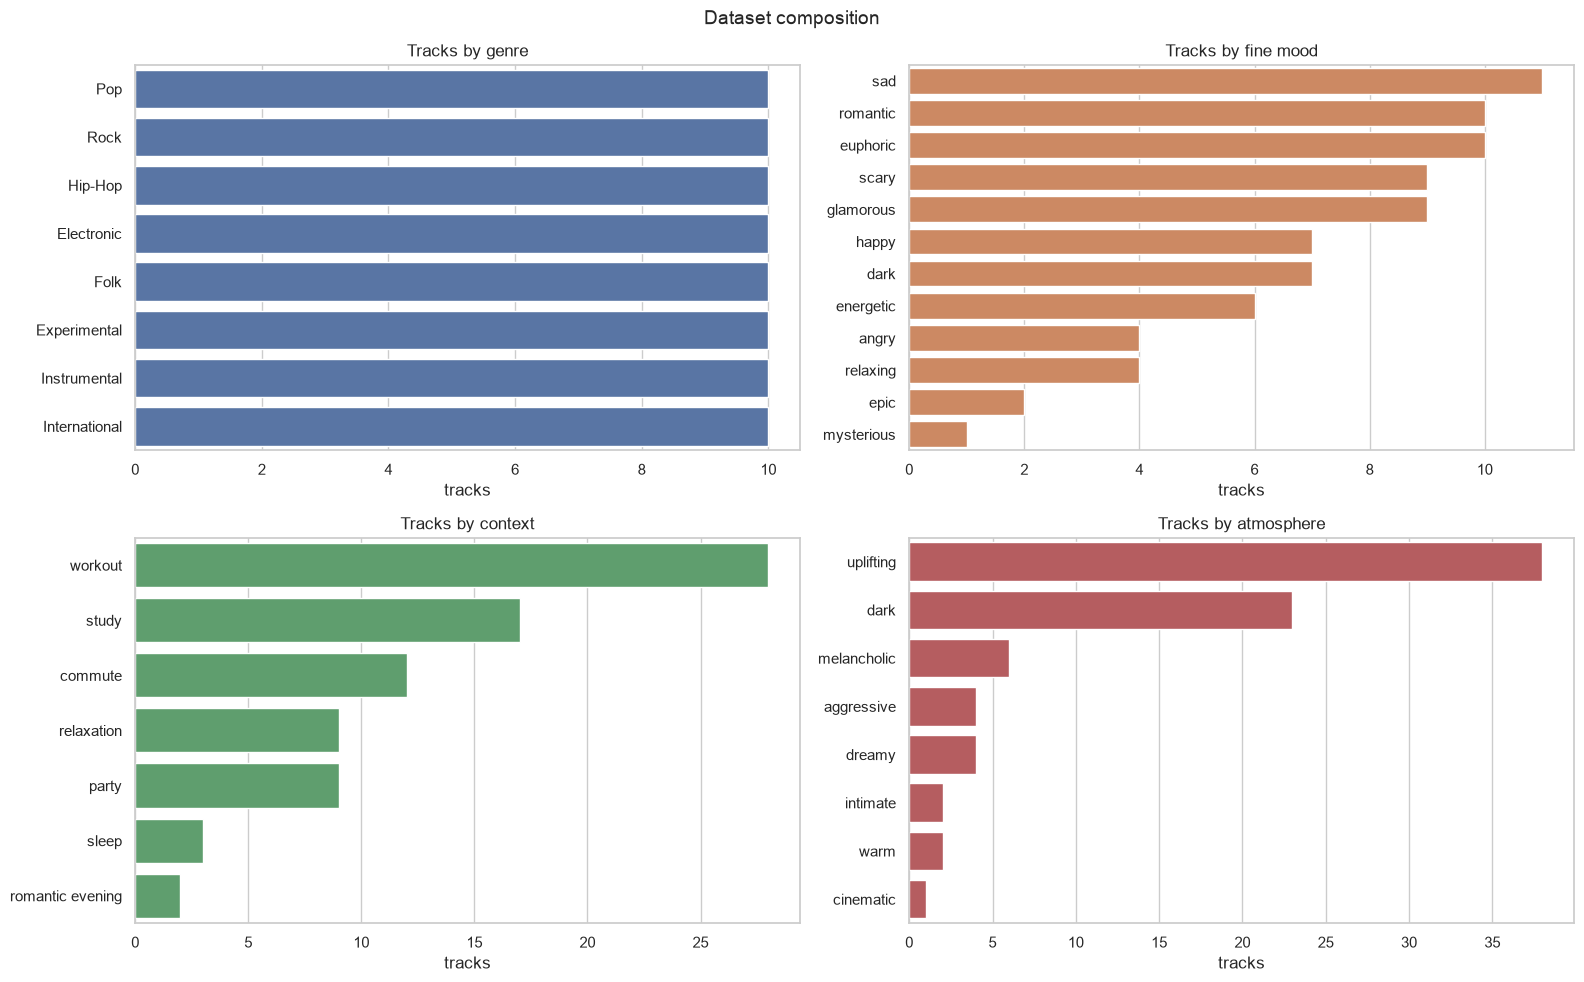

,count,mean,std,min,25%,50%,75%,max
tempo_bpm,80.0,121.156,30.566,47.852,98.464,117.454,143.555,215.332
rms_energy,80.0,0.201,0.077,0.033,0.146,0.198,0.258,0.384
spectral_centroid,80.0,1989.406,633.811,538.339,1606.782,2050.931,2463.855,3307.236
duration_sec,80.0,209.800,83.971,60.000,155.750,203.000,241.250,421.000
mood_confidence,80.0,0.525,0.178,0.249,0.357,0.536,0.686,0.788
mood_fine_confidence,80.0,0.261,0.076,0.158,0.231,0.249,0.265,0.625


tempo_category,slow,medium,fast
energy_level,,,
low,2,11,14
medium,2,10,14
high,7,11,9


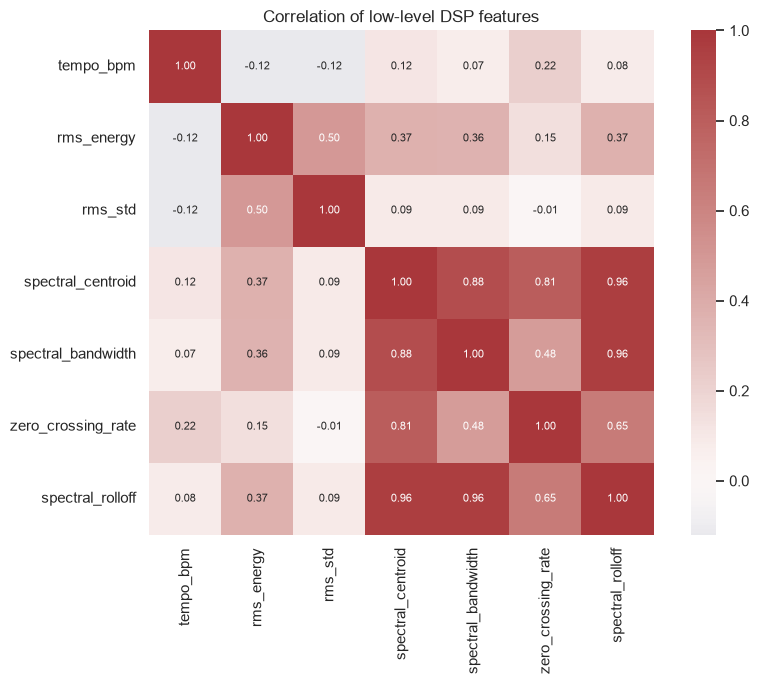

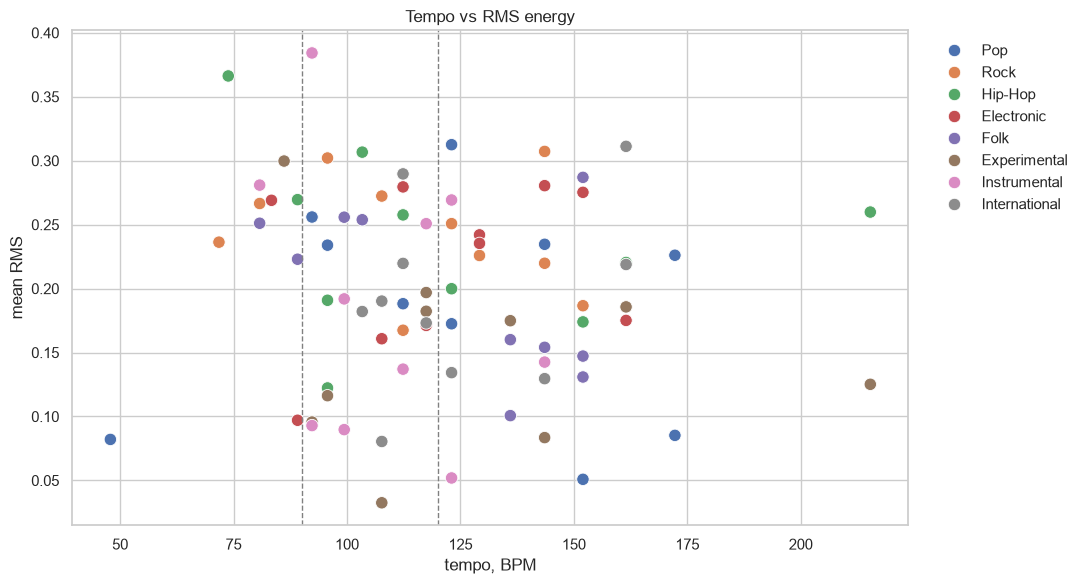

instrumental: {'vocal': 58, 'instrumental': 22}
energy: {'low': 27, 'high': 27, 'medium': 26}
tempo: {'fast': 37, 'medium': 32, 'slow': 11}
mean mood confidence: 0.525
mean fine mood confidence: 0.261


In [5]:
df = enriched.copy()

missing = df.isna().sum()
display(missing[missing > 0].to_frame("missing"))
display(df["era"].value_counts().rename_axis("era").to_frame("tracks"))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
sns.countplot(data=df, y="genre", order=df["genre"].value_counts().index, ax=axes[0, 0], color="#4C72B0")
axes[0, 0].set_title("Tracks by genre")
sns.countplot(data=df, y="mood_fine", order=df["mood_fine"].value_counts().index, ax=axes[0, 1], color="#DD8452")
axes[0, 1].set_title("Tracks by fine mood")
sns.countplot(data=df, y="context", order=df["context"].value_counts().index, ax=axes[1, 0], color="#55A868")
axes[1, 0].set_title("Tracks by context")
sns.countplot(data=df, y="atmosphere", order=df["atmosphere"].value_counts().index, ax=axes[1, 1], color="#C44E52")
axes[1, 1].set_title("Tracks by atmosphere")
for ax in axes.ravel():
    ax.set_xlabel("tracks")
    ax.set_ylabel("")
fig.suptitle("Dataset composition", fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_01_composition.png", dpi=160, bbox_inches="tight")
plt.show()

display(df[["tempo_bpm", "rms_energy", "spectral_centroid", "duration_sec", "mood_confidence", "mood_fine_confidence"]].describe().T.round(3))
display(pd.crosstab(df["energy_level"], df["tempo_category"]).reindex(index=["low", "medium", "high"], columns=["slow", "medium", "fast"]))

corr_columns = [
    "tempo_bpm", "rms_energy", "rms_std", "spectral_centroid",
    "spectral_bandwidth", "zero_crossing_rate", "spectral_rolloff",
]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_columns].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True, annot_kws={"size": 8})
plt.title("Correlation of low-level DSP features")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_02_correlation.png", dpi=160, bbox_inches="tight")
plt.show()

plt.figure(figsize=(11, 6))
sns.scatterplot(data=df, x="tempo_bpm", y="rms_energy", hue="genre", s=80, edgecolor="white", linewidth=0.6)
plt.axvline(90, color="gray", linestyle="--", linewidth=1)
plt.axvline(120, color="gray", linestyle="--", linewidth=1)
plt.title("Tempo vs RMS energy")
plt.xlabel("tempo, BPM")
plt.ylabel("mean RMS")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_03_tempo_energy.png", dpi=160, bbox_inches="tight")
plt.show()

print("instrumental:", df["instrumental"].value_counts().to_dict())
print("energy:", df["energy_level"].value_counts().to_dict())
print("tempo:", df["tempo_category"].value_counts().to_dict())
print("mean mood confidence:", round(float(df["mood_confidence"].mean()), 3))
print("mean fine mood confidence:", round(float(df["mood_fine_confidence"].mean()), 3))


### 3.1. Что видно

- Жанры строго сбалансированы: по 10 треков, это следствие дизайна выборки.
- Настроения — нет. Группа `happy` доминирует (40 треков), затем `dark` (24); `romantic` всего 2, а `nostalgic` и `epic` не встретились как максимум группы.
- Fine-mood распределён ровнее: `sad` 11, `romantic` 10, `euphoric` 10, `scary` 9, `glamorous` 9.
- Контексты смещены: `workout` 28, `study` 17, `commute` 12; `sleep` 3, `romantic evening` 2.
- Атмосферы тоже смещены: `uplifting` 38, `dark` 23; редкие классы — `cinematic` 1, `intimate` 2, `warm` 2.
- Темп: от 47.9 до 215.3 BPM, медиана 117.5. RMS: 0.03–0.38, медиана 0.20.
- 43 из 80 треков не имеют даты релиза; `era` для них `unknown`.
- Mood-модель уверена умеренно: средняя confidence группы 0.53, fine-mood — 0.26. Это ожидаемо для 30-секундных фрагментов и 14 классов.
- `rms_std` коррелирует с `rms_energy` (0.50), а спектральные признаки сильно коллинеарны: `spectral_centroid` ↔ `spectral_rolloff` 0.96, `spectral_bandwidth` ↔ `spectral_rolloff` 0.96, `spectral_centroid` ↔ `spectral_bandwidth` 0.88. Темп почти не связан с энергией (−0.12).
- Есть выбросы по темпу и длительности, но для content-based similarity они не удаляются: это реальные музыкальные различия.

### 3.2. Ограничения EDA

- Нет пользовательских оценок, поэтому нельзя измерить субъективную релевантность.
- Жанровые метки FMA неоднородны: `Experimental`, `Instrumental` и `International` — особенно широкие категории.
- Контекст и атмосфера — результат правил, поэтому их распределение отражает не «истину», а выбранную логику.


## 4. Похожесть, визуализация и рекомендации

### 4.1. Представления

| Представление | Вектор | Метрика |
|---|---|---|
| CLAP | 512d audio embedding, mean-centered | cosine |
| DSP | 39d, z-score | Euclidean |
| Semantic | mood + context + atmosphere + instrumental + energy + tempo | cosine |
| Hybrid | CLAP + DSP + Semantic, каждый блок L2-нормализован | cosine |

CLAP-эмбеддинги сильно анизотропны: сырые cosine-сходства лежат около 0.98–0.99. Для интерпретируемости выполняется mean-centering, после чего сходства становятся различимыми.

### 4.2. Как оцениваем

Для каждого трека берутся 5 ближайших соседей без самого себя. Считается `P@1` и `P@5` — доля соседей с тем же жанром, fine-mood и контекстом. Сравнение идёт со случайным baseline, который учитывает частоты классов.

Это косвенная оценка: жанр и настроение — не единственный смысл похожести. Но она позволяет сравнить представления между собой.


In [6]:
embeddings = np.load(CLAP_PATH)
dsp_data = np.load(DSP_PATH)
dsp_matrix = dsp_data["features"]
dsp_names = dsp_data["names"].tolist()
semantic_data = np.load(SEM_PATH, allow_pickle=True)

mood_group = semantic_data["mood_group"]
context_scores_matrix = semantic_data["context"]
atmosphere_scores_matrix = semantic_data["atmosphere"]
context_scores_matrix = context_scores_matrix - context_scores_matrix.min(axis=1, keepdims=True)
context_scores_matrix = context_scores_matrix / context_scores_matrix.sum(axis=1, keepdims=True)
atmosphere_scores_matrix = atmosphere_scores_matrix - atmosphere_scores_matrix.min(axis=1, keepdims=True)
atmosphere_scores_matrix = atmosphere_scores_matrix / atmosphere_scores_matrix.sum(axis=1, keepdims=True)

instrumental_vector = (df["instrumental"] == "instrumental").astype(float).values[:, None]
energy_matrix = pd.get_dummies(df["energy_level"]).reindex(columns=["low", "medium", "high"], fill_value=0).astype(float).values
tempo_matrix = pd.get_dummies(df["tempo_category"]).reindex(columns=["slow", "medium", "fast"], fill_value=0).astype(float).values
semantic_profile = np.hstack([
    mood_group,
    context_scores_matrix,
    atmosphere_scores_matrix,
    instrumental_vector,
    energy_matrix,
    tempo_matrix,
])

clap_centered = embeddings - embeddings.mean(axis=0)
dsp_scaled = StandardScaler().fit_transform(dsp_matrix)


def cosine_similarity(matrix):
    normalized = normalize(matrix)
    return normalized @ normalized.T


def euclidean_similarity(matrix):
    return -pairwise_distances(matrix, metric="euclidean")


representations = {
    "CLAP": cosine_similarity(clap_centered),
    "DSP": euclidean_similarity(dsp_scaled),
    "Semantic": cosine_similarity(semantic_profile),
    "Hybrid": cosine_similarity(np.hstack([
        normalize(clap_centered),
        normalize(dsp_scaled),
        normalize(semantic_profile),
    ])),
}


def ranking_metrics(similarity, column, k=5):
    labels = df[column].values
    precision_1 = []
    precision_5 = []
    for index in range(len(df)):
        order = np.argsort(-similarity[index])
        order = [candidate for candidate in order if candidate != index][:k]
        precision_1.append(labels[order[0]] == labels[index])
        precision_5.append(np.mean(labels[order] == labels[index]))
    return float(np.mean(precision_1)), float(np.mean(precision_5))


metric_rows = {}
for name, similarity in representations.items():
    metric_rows[name] = {}
    for column, prefix in [("genre", "genre"), ("mood_fine", "mood"), ("context", "context")]:
        p1, p5 = ranking_metrics(similarity, column)
        metric_rows[name][f"{prefix}_P@1"] = p1
        metric_rows[name][f"{prefix}_P@5"] = p5

random_row = {}
for column, prefix in [("genre", "genre"), ("mood_fine", "mood"), ("context", "context")]:
    counts = df[column].value_counts()
    random_row[f"{prefix}_P@1"] = float(np.mean((df[column].map(counts) - 1) / (len(df) - 1)))
    random_row[f"{prefix}_P@5"] = random_row[f"{prefix}_P@1"]
metric_rows["Random"] = random_row

metric_columns = ["genre_P@1", "genre_P@5", "mood_P@1", "mood_P@5", "context_P@1", "context_P@5"]
metrics = pd.DataFrame(metric_rows).T[metric_columns]
display(metrics.round(3))
metrics.to_csv(DATA_DIR / "similarity_metrics.csv")

silhouette_values = {
    column: float(silhouette_score(clap_centered, df[column], metric="cosine"))
    for column in ["genre", "mood_fine", "context"]
}
display(pd.Series(silhouette_values, name="silhouette").to_frame().round(3))


,genre_P@1,genre_P@5,mood_P@1,mood_P@5,context_P@1,context_P@5
CLAP,0.150,0.170,0.162,0.118,0.338,0.277
DSP,0.300,0.175,0.188,0.150,0.275,0.225
Semantic,0.212,0.145,0.288,0.167,0.850,0.653
Hybrid,0.212,0.195,0.212,0.180,0.575,0.450
Random,0.114,0.114,0.091,0.091,0.208,0.208


,silhouette
genre,-0.158
mood_fine,-0.343
context,-0.212


### 4.3. Результаты сравнения

Random baseline: жанр 0.114, fine-mood 0.091, контекст 0.208. Это ожидаемая доля случайного совпадения с учётом частот классов.

- **CLAP** даёт `genre P@5 = 0.170`, `mood P@5 = 0.118`, `context P@5 = 0.277`. Это выше random, но настроение ловится слабо.
- **DSP** неожиданно силён на `genre P@1 = 0.300`: темп и тембр хорошо выделяют отдельные жанры. Но на `P@5` он слабее — 0.175.
- **Semantic** почти не помогает жанру (0.145), зато ожидаемо сильно совпадает по контексту (0.653). Это circular-эффект: контекст сам является признаком.
- **Hybrid** — лучший компромисс: `genre P@5 = 0.195`, `mood P@5 = 0.180`, `context P@5 = 0.450`. Контекст здесь тоже завышен из-за rule-based профиля.
- Силуэт в CLAP-пространстве отрицательный: жанр −0.158, fine-mood −0.343, контекст −0.212. Глобальных кластеров нет.

Вывод: локальная похожесть работает лучше, чем глобальная кластеризация. Это типично для малого и разнородного музыкального датасета.


### 4.4. UMAP

UMAP строится на mean-centered CLAP-эмбеддингах с cosine-метрикой. Цвет — жанр и fine-mood. Это визуальная проверка гипотезы о кластерах, а не доказательство качества.


/Users/dotamaster2/Documents/music_recommendation_semantics/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


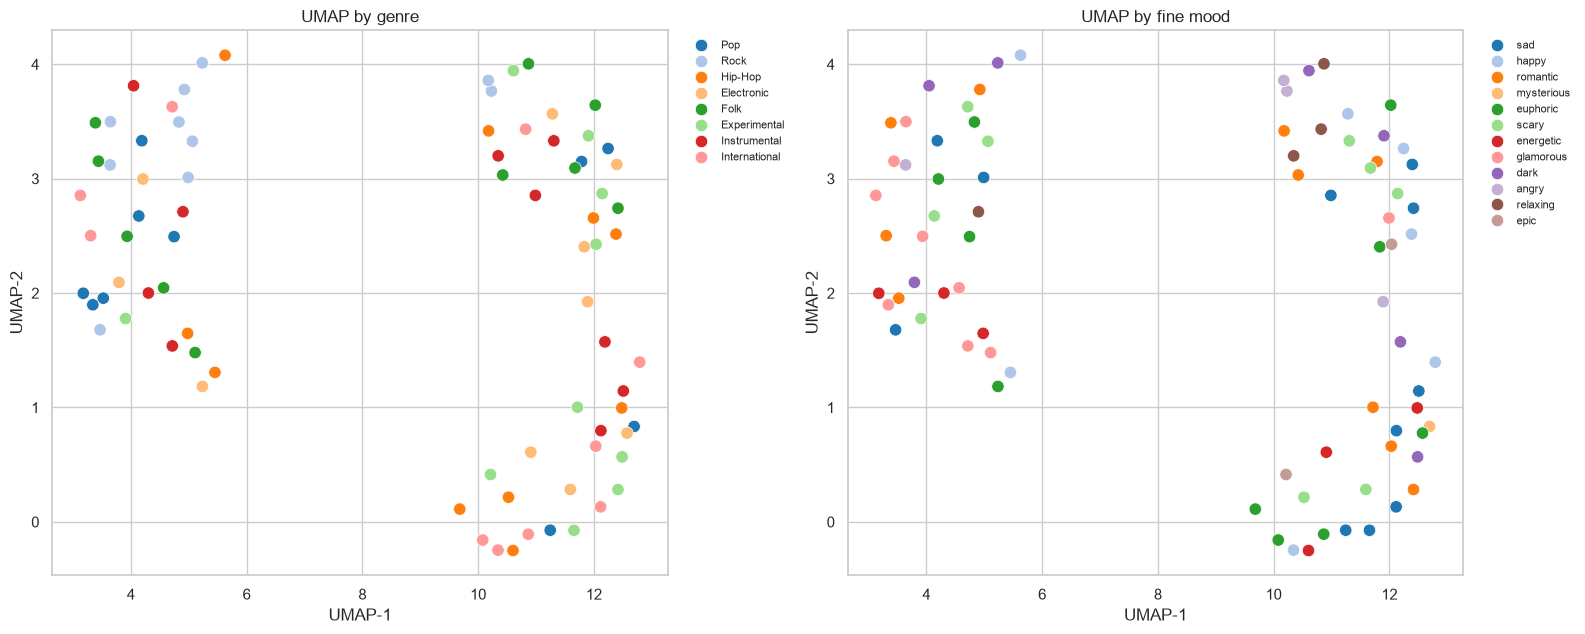

,track_uid,title,artist,genre,mood,mood_fine,context,umap_1,umap_2d
0,F054033,Snow Wave,alright lover,Pop,sad,sad,sleep,11.245542,-0.072838
1,F062751,Birthday Cake,Jahzzar,Pop,happy,happy,relaxation,12.245493,3.263460
2,F042751,Butterfly,Delicate Steve,Pop,romantic,romantic,romantic evening,11.787054,3.149653
3,F000010,Freeway,Kurt Vile,Pop,sad,sad,relaxation,4.187917,3.331634
4,F010805,Super Nude,Lesbian Afternoon,Pop,happy,romantic,commute,3.522556,1.955328


In [7]:
reducer = umap.UMAP(n_neighbors=12, min_dist=0.15, metric="cosine", random_state=SEED)
umap_2d = reducer.fit_transform(clap_centered)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, column, title in [
    (axes[0], "genre", "UMAP by genre"),
    (axes[1], "mood_fine", "UMAP by fine mood"),
]:
    sns.scatterplot(
        x=umap_2d[:, 0], y=umap_2d[:, 1], hue=df[column], palette="tab20",
        s=80, edgecolor="white", linewidth=0.5, ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_04_umap.png", dpi=160, bbox_inches="tight")
plt.show()

umap_frame = pd.DataFrame({
    "track_uid": df["track_uid"],
    "title": df["title"],
    "artist": df["artist"],
    "genre": df["genre"],
    "mood": df["mood"],
    "mood_fine": df["mood_fine"],
    "context": df["context"],
    "umap_1": umap_2d[:, 0],
    "umap_2d": umap_2d[:, 1],
})
umap_frame.to_csv(DATA_DIR / "umap_coordinates.csv", index=False)
display(umap_frame.head())


На UMAP нет чистых жанровых островов: точки разных жанров перемешаны, а отрицательный silhouette это подтверждает. При этом локальные соседи чаще совпадают по жанру и контексту, чем случайные пары. Визуально это выглядит как несколько размытых областей, а не как 8 отдельных кластеров.

Причины: 80 треков, 30-секундные фрагменты, широкие жанровые метки и высокая анизотропия CLAP. Для более убедительной кластеризации нужен датасет в сотни раз больше или fine-tuning под жанр/настроение.


### 4.5. Примеры рекомендаций

Ниже — top-5 соседей по Hybrid-представлению для четырёх треков из разных жанров. Показаны жанр, настроение, контекст и атмосфера, чтобы можно было проверить не только метрику, но и смысл выдачи.


In [8]:
hybrid_similarity = representations["Hybrid"]
seed_titles = ["These Days", "Fater Lee", "Snow Wave", "Kopeika"]

examples = []
for seed_title in seed_titles:
    seed_index = int(df.index[df["title"] == seed_title][0])
    order = np.argsort(-hybrid_similarity[seed_index])
    order = [candidate for candidate in order if candidate != seed_index][:5]
    block = df.loc[order, ["title", "artist", "genre", "mood", "context", "atmosphere"]].copy()
    block.insert(0, "score", hybrid_similarity[seed_index, order])
    block.insert(0, "seed", seed_title)
    examples.append(block)

recommendations = pd.concat(examples, ignore_index=True)
display(recommendations.round(3))

for seed_title in seed_titles:
    seed_row = df.loc[df["title"] == seed_title].iloc[0]
    print(
        f"{seed_title} | {seed_row['artist']} | {seed_row['genre']} | "
        f"{seed_row['mood']} | {seed_row['context']} | {seed_row['atmosphere']}"
    )


,seed,score,title,artist,genre,mood,context,atmosphere
0,These Days,0.545,The One,Eric Eckhart plus Salonband,Folk,happy,workout,uplifting
1,These Days,0.539,Cupido,Frank Guerrero y Su Grupo Aché,International,happy,commute,uplifting
2,These Days,0.506,Starkey,Koona,Electronic,happy,party,uplifting
3,These Days,0.491,Marktversagen,Von Korf,Rock,happy,party,uplifting
4,These Days,0.484,I Feel Fantastic,Jonathan Coulton,Folk,happy,party,uplifting
5,Fater Lee,0.553,Be Sweet,Marco Trovatello,Rock,dark,workout,dark
6,Fater Lee,0.491,Midori,Beat Culture,Electronic,dark,workout,dark
7,Fater Lee,0.380,Night Owl,Broke For Free,Electronic,happy,commute,uplifting
8,Fater Lee,0.348,all these wires between us,Lucky Dragons,Experimental,dark,workout,dark
9,Fater Lee,0.339,11 strANGE Ls,Mark Neil,Instrumental,dark,workout,dark


These Days | Robin Grey | Folk | happy | party | uplifting
Fater Lee | Black Ant | Hip-Hop | dark | workout | cinematic
Snow Wave | alright lover | Pop | sad | sleep | melancholic
Kopeika | et_ | Rock | happy | workout | uplifting


### 4.6. Интерпретация выдачи

- Для `These Days` (Folk, happy) Hybrid находит другие Folk/happy треки и близкие по контексту записи; это ожидаемо.
- Для `Fater Lee` (Hip-Hop, dark) в top-5 попадают dark/workout треки других жанров. Это пример кросс-жанровой семантической похожести.
- Для `Snow Wave` (Pop, sad) находятся sad/sleep и близкие по атмосфере треки, но не всегда Pop. Для пользователя это может быть полезнее, чем формальный жанр.
- Для `Kopeika` (Rock, happy) выдача смешивает Rock, Hip-Hop и International с общим контекстом workout.

Именно поэтому Hybrid — практичный вариант: CLAP даёт тембр, DSP — темп/энергию, семантика — настроение и сценарий. Но контекстные метрики нельзя считать независимой оценкой: контекст уже включён в вектор.


## 5. Выводы

### 5.1. Что сделано

- Собран воспроизводимый датасет из 80 треков FMA: 8 жанров, открытые лицензии, 30-секундные mp3.
- Реализован пайплайн: FMA metadata → отбор → Range-загрузка аудио → DSP → CLAP → mood-модель → контекст/атмосфера → enriched CSV.
- Проведён EDA: состав, распределения, корреляции, ограничения.
- Построены четыре similarity-представления, посчитаны `P@1`/`P@5`, UMAP и примеры top-5.
- Все результаты сохранены в `data/` и `figures/`.

### 5.2. Главный ответ

Признаки **частично** отражают реальную похожесть. Локальные соседи чаще случайного совпадают по жанру, настроению и контексту, но глобальных кластеров нет. Лучший практический вариант — Hybrid: CLAP + DSP + семантический профиль.

Ключевые числа:

- Hybrid: `genre P@5 = 0.195` против random 0.114; `mood P@5 = 0.180` против 0.091.
- CLAP: `genre P@5 = 0.170`; DSP: `genre P@1 = 0.300`.
- Silhouette в CLAP-пространстве отрицательный, UMAP не показывает чистых жанровых кластеров.

### 5.3. Ограничения

- Мало данных: 80 треков и 30 секунд на трек.
- Жанры FMA широкие и местами шумные.
- Mood-модель обучена на другом домене и даёт невысокую confidence.
- Контекст и атмосфера — субъективные rule-based метки, а не ground truth.
- Нет пользовательских взаимодействий и A/B-оценки.
- Метрики `P@5` по жанру и настроению — косвенные; они не равны удовлетворённости пользователя.

### 5.4. Что улучшить

- Увеличить датасет и добавить полные треки.
- Fine-tune CLAP или обучить metric learning на парах «похоже / не похоже».
- Обучить отдельный контекстный классификатор на размеченных данных.
- Добавить пользовательские лайки/скипы и обучать веса Hybrid-модели.
- Провести human evaluation: попросить людей оценить top-5 для 20–30 seed-треков.
- Добавить фильтры по инструментальности, эпохе и темпу в интерфейс рекомендаций.

### 5.5. Итог

Получен честный baseline, который можно воспроизвести, объяснить и улучшать. Он не «решает» музыкальные рекомендации, но показывает полный цикл: данные → признаки → EDA → similarity → визуализация → выводы, а также явно фиксирует, где модель ошибается и почему.
